# Smart Watering: Decision Tree (final model)
ICS 3202 | Deliverable 3 | Kiprotich, Ian - 192026, Jethwa, Devyan - 183428 and Gitonga, Alfred - 166342

**Question:** Can a decision tree predict when an outdoor garden plant needs water?

**How this notebook is organised** (the stages of the data-mining process):

| Stage | Where |
|---|---|
| 1. Business understanding | The problem, the user and what success means |
| 2. Data understanding | Section 1: Ian, loading and checking the weather data |
| 3. Data preparation | Section 2: Devyan, plants, labels, model inputs and exploration |
| 4. Modelling | Section 3.1 to 3.2: Alfred, split and tuning |
| 5. Evaluation | Section 3.3 to 3.7: Alfred, test, comparison, findings and limitations |
| 6. Deployment | Appendix: Alfred, model files, input limits and how the model explains a decision |

If anyone wants to test and run the notebook from the top with **Restart and Run all**.

# Stage 1: Business understanding
**Who it is for:** a home gardener in Nairobi (our example user is Florence) with a handful of mixed plants and little time.

**The problem:** watering on a fixed schedule wastes water after rain and misses dry spells. The app has no soil sensor.

**What the model does:** each morning it uses the last few days of weather, the plant's species and when the gardener last watered it, and answers **water now** or **not yet**.

**What success looks like:**
- it does better than a fixed watering calendar;
- it can explain each answer in plain words;
- it is small enough to run offline on a phone.

**What we can and cannot claim:** the watering labels are simulated from real weather, so the scores show how well the tree learns our simulated rule. They do not yet show results on real plants.

### Plain-language guide
- **Decision tree:** a flowchart of yes/no questions. Each answer sends you down a branch until you reach an answer.
- **Leaf:** the end of a branch, where the tree gives its answer (water now or not yet).
- **Kc:** how much water a plant type uses compared with a reference grass.
- **ET0:** how much water a reference grass would lose to evaporation in a day, worked out from the weather.
- **Precision, recall, F1:** precision is how many of the "water" alerts were right; recall is how many of the days that needed water were caught; F1 is one score that balances the two.
- **Why accuracy misleads here:** most days need no watering, so a model that always says "wait" scores about 83% (83.2% in this notebook) yet never waters anything. That is why we also report balanced accuracy and F1.
- **Balanced accuracy:** the average of how well each class is caught (the "water" days and the "wait" days). Always-wait scores 50%.
- **Cross-validation:** the training data is split into 5 parts, and each part takes a turn as a practice test, so settings are chosen without touching the final test set.
- **Stratified:** every split keeps the same share of "water" days.
- **Data leakage:** when the model gets information it would not have in real use, such as today's weather.

# Stage 2: Data understanding
*Sections 1.1 to 1.6: loading and checking the weather data.*

## 1. Ian: Data and cleaning
### 1.1 Our approach
We use **supervised binary classification**: water today (1) or wait (0). The base model is a Decision Tree. The app is intended to work without soil sensors.


In [1]:
from pathlib import Path
import json, hashlib, platform, importlib.metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import requests
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score,balanced_accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
VERSIONS = {p: importlib.metadata.version(p) for p in
            ["numpy", "pandas", "matplotlib", "seaborn", "scikit-learn", "requests", "joblib"]}


### 1.2 Load the weather data
We use daily ERA5 weather for Nairobi, 2015-2025, from Open-Meteo. The CSV and source details are saved so we can repeat the run.


In [2]:
URL = "https://archive-api.open-meteo.com/v1/archive"
PARAMS = {"latitude": -1.2921, "longitude": 36.8219,
          "start_date": "2015-01-01", "end_date": "2025-12-31",
          "daily": "temperature_2m_max,temperature_2m_min,temperature_2m_mean,relative_humidity_2m_mean,precipitation_sum,et0_fao_evapotranspiration,wind_speed_10m_max",
          "timezone": "Africa/Nairobi", "models": "era5",
          "temperature_unit": "celsius", "wind_speed_unit": "kmh", "precipitation_unit": "mm"}
RAW_PATH = Path("nairobi_era5_daily_2015_2025.csv")
META_PATH = Path("weather_provenance.json")
if RAW_PATH.exists():
    if not META_PATH.exists():
        raise ValueError("Cached CSV has no provenance. Restore its metadata or rename the CSV and rerun.")
    provenance = json.loads(META_PATH.read_text())
    assert provenance["request"] == PARAMS, "Cached request does not match this notebook."
    assert hashlib.sha256(RAW_PATH.read_bytes()).hexdigest() == provenance["sha256"], "Cached CSV checksum mismatch."
    raw = pd.read_csv(RAW_PATH)
else:
    response = requests.get(URL, params=PARAMS, timeout=120)
    response.raise_for_status()
    payload = response.json()
    if payload.get("error"):
        raise ValueError(payload.get("reason", "Weather API error"))
    raw = pd.DataFrame(payload["daily"])
    raw.to_csv(RAW_PATH, index=False)
    provenance = {"source": URL, "request": PARAMS, "resolved_url": response.url,
                  "retrieved_utc": pd.Timestamp.now(tz="UTC").isoformat(),
                  "daily_units": payload["daily_units"],
                  "location": {k: payload.get(k) for k in ["latitude", "longitude", "elevation", "timezone"]},
                  "sha256": hashlib.sha256(RAW_PATH.read_bytes()).hexdigest()}
    META_PATH.write_text(json.dumps(provenance, indent=2))
print("Source:", provenance["source"], "| requested model:", PARAMS["models"])
print("Location:", provenance["location"])
print("Raw shape:", raw.shape, "| SHA256:", provenance["sha256"])
display(raw.head())


Source: https://archive-api.open-meteo.com/v1/archive | requested model: era5
Location: {'latitude': -1.25, 'longitude': 36.75, 'elevation': 1668.0, 'timezone': 'Africa/Nairobi'}
Raw shape: (4018, 8) | SHA256: b5d3ab20d074e95a4b76428d4f21974494224c0c9e6aaac9aeaf036a67dfcebb


,time,temperature_2m_max,temperature_2m_min,temperature_2m_mean,relative_humidity_2m_mean,precipitation_sum,et0_fao_evapotranspiration,wind_speed_10m_max
0,2015-01-01,28.0,12.6,20.3,52,0.0,5.84,18.3
1,2015-01-02,28.6,11.9,20.8,42,0.0,6.66,19.1
2,2015-01-03,29.5,12.7,20.9,40,0.0,6.22,18.3
3,2015-01-04,30.2,13.3,21.5,40,0.0,5.62,12.6
4,2015-01-05,29.8,13.8,21.8,49,0.0,4.71,11.9


### 1.3 Fix the format and check missing values
Convert the date and numeric columns, then sort by date. Missing rainfall is not treated as zero. Missing data must be resolved before modelling.


In [3]:
print(raw.dtypes)
weather = raw.rename(columns={"time": "date", "temperature_2m_max": "temp_max",
    "temperature_2m_min": "temp_min", "temperature_2m_mean": "temp_mean",
    "relative_humidity_2m_mean": "humidity_mean", "precipitation_sum": "rain",
    "et0_fao_evapotranspiration": "et0", "wind_speed_10m_max": "wind_max"}).copy()
weather["date"] = pd.to_datetime(weather["date"], errors="raise")
num_cols = ["temp_max", "temp_min", "temp_mean", "humidity_mean", "rain", "et0", "wind_max"]
weather[num_cols] = weather[num_cols].apply(pd.to_numeric, errors="raise")
weather = weather.sort_values("date").reset_index(drop=True)
print("After renaming, conversion and sorting:", weather.shape)
display(weather.dtypes)

print(weather.isna().sum())
assert not weather.isna().any().any(), "Missing data: resolve from the source before simulation. Missing rain is not zero rain."
assert np.isfinite(weather[num_cols].to_numpy()).all(), "Non-finite weather values."
print("No missing values. No interpolation or zero-rain filling applied.")


time                           object
temperature_2m_max            float64
temperature_2m_min            float64
temperature_2m_mean           float64
relative_humidity_2m_mean       int64
precipitation_sum             float64
et0_fao_evapotranspiration    float64
wind_speed_10m_max            float64
dtype: object
After renaming, conversion and sorting: (4018, 8)


,0
date,datetime64[ns]
temp_max,float64
temp_min,float64
temp_mean,float64
humidity_mean,int64
rain,float64
et0,float64
wind_max,float64


date             0
temp_max         0
temp_min         0
temp_mean        0
humidity_mean    0
rain             0
et0              0
wind_max         0
dtype: int64
No missing values. No interpolation or zero-rain filling applied.


### 1.4 Check duplicates, dates and ranges
Remove exact duplicates. Stop if dates are missing, readings conflict, or values fail our checks.


In [4]:
print("Duplicate dates:", int(weather["date"].duplicated().sum()))
# Remove only exact duplicate rows. Conflicting readings for the same date need review.
before = len(weather)
weather = weather.drop_duplicates().reset_index(drop=True)
print("Exact duplicate rows removed:", before - len(weather))
assert not weather["date"].duplicated().any(), "Conflicting duplicate dates need source review."
full_range = pd.date_range(PARAMS["start_date"], PARAMS["end_date"], freq="D")
missing_days = full_range.difference(weather["date"])
extra_days = pd.DatetimeIndex(weather["date"]).difference(full_range)
print("Expected:", len(full_range), "Present:", len(weather), "Missing:", len(missing_days), "Extra:", len(extra_days))
assert len(missing_days) == len(extra_days) == 0, "Resolve calendar gaps before rolling features or simulation."

checks = {
    "temperature plausibility (-5 to 45 C)": weather[["temp_min", "temp_mean", "temp_max"]].apply(lambda x: x.between(-5, 45)).all(axis=1),
    "min <= mean <= max": (weather["temp_min"] <= weather["temp_mean"]) & (weather["temp_mean"] <= weather["temp_max"]),
    "humidity 0 to 100": weather["humidity_mean"].between(0, 100),
    "rain non-negative": weather["rain"] >= 0,
    "ET0 non-negative": weather["et0"] >= 0,
    "wind non-negative": weather["wind_max"] >= 0}
valid = pd.DataFrame(checks)
print("Rows flagged by each check:")
print((~valid).sum())
assert valid.all().all(), "Flagged rows require source review. Do not delete dates and silently bridge the gap."
print("All checks passed. Rows removed by range checks: 0")


Duplicate dates: 0
Exact duplicate rows removed: 0
Expected: 4018 Present: 4018 Missing: 0 Extra: 0
Rows flagged by each check:
temperature plausibility (-5 to 45 C)    0
min <= mean <= max                       0
humidity 0 to 100                        0
rain non-negative                        0
ET0 non-negative                         0
wind non-negative                        0
dtype: int64
All checks passed. Rows removed by range checks: 0


### 1.5 Check unusual values
We keep unusual readings that pass the checks. A heavy-rain day is not automatically a data error.


temp_mean          6
temp_max          20
humidity_mean     26
rain             566
et0                2
wind_max           0
dtype: int64


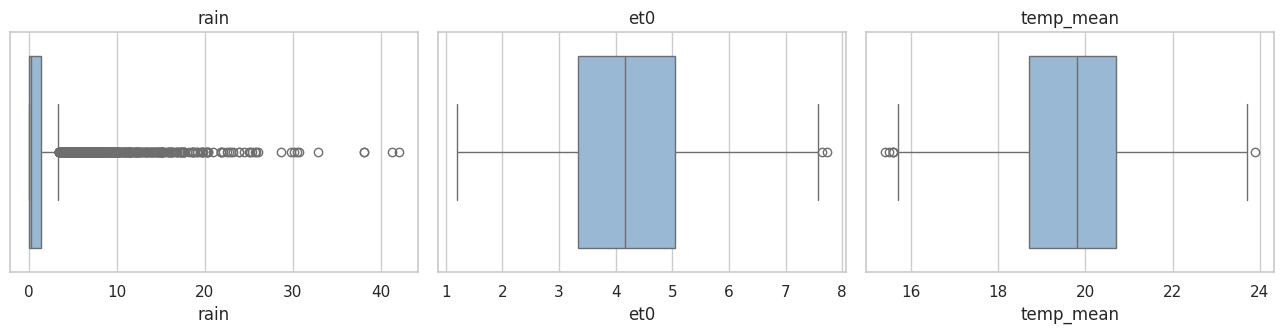

Cleaned weather: (4018, 8)
Dates: 2015-01-01 to 2025-12-31


In [5]:
# IQR rule: a value is an 'outlier' if it is more than 1.5 x IQR beyond the middle 50%
def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()

outlier_counts = weather[["temp_mean", "temp_max", "humidity_mean", "rain", "et0", "wind_max"]].apply(iqr_outliers)
print(outlier_counts)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for ax, col in zip(axes, ["rain", "et0", "temp_mean"]):
    sns.boxplot(x=weather[col], ax=ax, color="#8fb8de")
    ax.set_title(col)
plt.tight_layout(); plt.show()
print("Cleaned weather:", weather.shape)
print("Dates:", weather["date"].min().date(), "to", weather["date"].max().date())


### 1.6 Observation 1: Rainfall through the year
The chart compares monthly rainfall and water demand. We use it to identify wetter and drier periods.


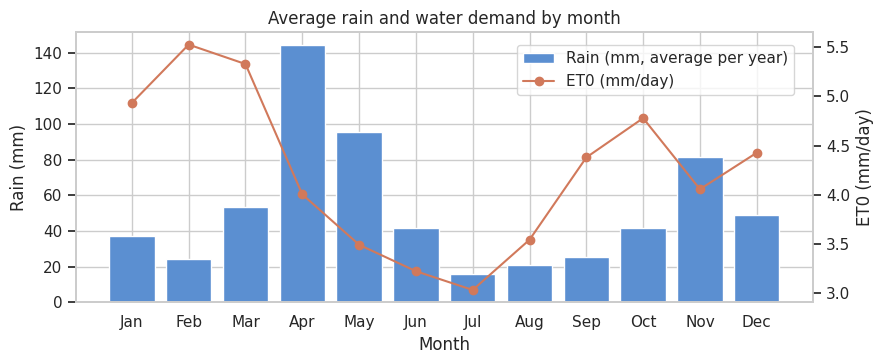

Observation 1: the wettest months are Apr, May, Nov, Mar, averaging 94 mm each, while the driest months are Feb, Aug, Jul at 20 mm each. ET0 (water demand) is highest in Feb (5.52 mm/day) and lowest in Jul (3.03 mm/day).


In [6]:
monthly = weather.assign(month=weather["date"].dt.month).groupby("month").agg(
    rain_mm_per_year=("rain", lambda s: s.sum() / weather["date"].dt.year.nunique()),
    et0_mm_per_day=("et0", "mean"))

fig, ax1 = plt.subplots(figsize=(9, 3.8))
ax1.bar(monthly.index, monthly["rain_mm_per_year"], color="#5b8fd1", label="Rain (mm, average per year)")
ax1.set_xlabel("Month"); ax1.set_ylabel("Rain (mm)")
ax1.set_xticks(range(1, 13), ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
ax2 = ax1.twinx()
ax2.plot(monthly.index, monthly["et0_mm_per_day"], color="#d1795b", marker="o", label="ET0 (mm/day)")
ax2.set_ylabel("ET0 (mm/day)"); ax2.grid(False)
fig.legend(loc="upper right", bbox_to_anchor=(0.9, 0.88)); plt.title("Average rain and water demand by month")
plt.tight_layout(); plt.show()

import calendar
name = lambda m: calendar.month_abbr[m]          # 3 -> 'Mar'
top = monthly["rain_mm_per_year"].sort_values(ascending=False)
print(f"Observation 1: the wettest months are {', '.join(name(m) for m in top.index[:4])}, averaging "
      f"{top.iloc[:4].mean():.0f} mm each, while the driest months are {', '.join(name(m) for m in top.index[-3:])} "
      f"at {top.iloc[-3:].mean():.0f} mm each. ET0 (water demand) is highest in {name(monthly['et0_mm_per_day'].idxmax())} "
      f"({monthly['et0_mm_per_day'].max():.2f} mm/day) and lowest in {name(monthly['et0_mm_per_day'].idxmin())} "
      f"({monthly['et0_mm_per_day'].min():.2f} mm/day).")


# Stage 3: Data preparation
*Sections 2.1 to 2.6: build the labelled dataset, then explore it.*

## 2. Devyan: Labels and exploration
### 2.1 Choose the plant groups
These five outdoor plant groups use assumed coefficients, root depths and soil capacity. The values need field validation. Rainfall applies only to plants exposed to rain.

Real plants of the same species differ (pot size, soil mix, sun, shade), so we create **4 individual plants per group** with their own true water use, soil and root depth (about +/-20%). The labels use the true values. The model only sees the species values, like the app.


In [7]:
plants = pd.DataFrame([
    # group,            example,              kc,   root_m, p,    schedule_days
    ("succulent",       "aloe, cactus",       0.20, 0.25,   0.70, 10),
    ("herb",            "rosemary, thyme",    0.30, 0.25,   0.60, 7),
    ("flowering",       "marigold, petunia",  0.50, 0.20,   0.50, 3),
    ("fern",            "Boston fern",        0.80, 0.20,   0.35, 3),
    ("leafy_vegetable", "sukuma wiki (kale)", 1.00, 0.30,   0.45, 2),
], columns=["group", "example", "kc", "root_m", "p", "schedule_days"])

#
AVAILABLE_WATER = 0.14
plants["taw_mm"] = 1000 * AVAILABLE_WATER * plants["root_m"]
plants["threshold_mm"] = (plants["p"] * plants["taw_mm"]).round(1)

PLANTS_PER_GROUP = 4
rng = np.random.default_rng(RANDOM_STATE)
individuals = []
for g in plants.itertuples():
    for k in range(PLANTS_PER_GROUP):
        true_kc = g.kc * rng.uniform(0.8, 1.2)                 # +/- 20% water use
        true_aw = rng.uniform(0.10, 0.18)                      # soil holds 0.10-0.18 m3/m3
        true_root = g.root_m * rng.uniform(0.8, 1.2)           # +/- 20% root depth
        true_p = float(np.clip(g.p + rng.uniform(-0.1, 0.1), 0.2, 0.8))
        individuals.append({"plant_id": f"{g.group}_{k + 1}", "group": g.group,
                            "kc": g.kc, "threshold_mm": g.threshold_mm, "schedule_days": g.schedule_days,
                            "true_kc": round(true_kc, 3),
                            "true_threshold_mm": round(true_p * 1000 * true_aw * true_root, 1)})
individuals = pd.DataFrame(individuals)
display(plants)
display(individuals.head(8))
print(f"{len(individuals)} individual plants ({PLANTS_PER_GROUP} per group)")

,group,example,kc,root_m,p,schedule_days,taw_mm,threshold_mm
0,succulent,"aloe, cactus",0.2,0.25,0.70,10,35.0,24.5
1,herb,"rosemary, thyme",0.3,0.25,0.60,7,35.0,21.0
2,flowering,"marigold, petunia",0.5,0.20,0.50,3,28.0,14.0
3,fern,Boston fern,0.8,0.20,0.35,3,28.0,9.8
4,leafy_vegetable,sukuma wiki (kale),1.0,0.30,0.45,2,42.0,18.9


,plant_id,group,kc,threshold_mm,schedule_days,true_kc,true_threshold_mm
0,succulent_1,succulent,0.2,24.5,10,0.222,28.6
1,succulent_2,succulent,0.2,24.5,10,0.168,37.2
2,succulent_3,succulent,0.2,24.5,10,0.170,25.3
3,succulent_4,succulent,0.2,24.5,10,0.212,26.2
4,herb_1,herb,0.3,21.0,7,0.307,18.6
5,herb_2,herb,0.3,21.0,7,0.331,25.9
6,herb_3,herb,0.3,21.0,7,0.333,14.5
7,herb_4,herb,0.3,21.0,7,0.259,29.4


20 individual plants (4 per group)


### 2.2 Create the watering labels
Each day, plant demand increases the estimated soil deficit and rain reduces it. Reaching the threshold gives label 1, followed by an assumed full refill. These are **simulated labels**, using a simplified balance inspired by FAO-56.

Two realism settings apply. First, the app decides at 7 a.m., so every weather input is from yesterday or the last 3 days, never today. Second, the gardener is imperfect: a thirsty plant is watered that day only half the time (`NOTICE_PROB = 0.5`), and sometimes plants are watered out of habit (`HABIT_PROB = 0.05`). These settings were fixed before looking at any scores.


In [8]:
MIN_EFFECTIVE_RAIN = 2.0   # mm

w = weather[["date", "temp_mean", "temp_max", "humidity_mean", "wind_max", "rain", "et0"]].copy()
w["effective_rain"] = np.where(w["rain"] >= MIN_EFFECTIVE_RAIN, w["rain"], 0.0)

# REALISM 2: the app decides at 7 a.m., before today's weather has happened.
# Every weather input is from YESTERDAY or the last 3 days, never today.
for col in ["temp_mean", "temp_max", "humidity_mean", "wind_max", "rain", "et0"]:
    w[f"{col}_yday"] = w[col].shift(1)
w["rain_last_3d"] = w["rain"].rolling(3, min_periods=1).sum().shift(1)
w["et0_last_3d"] = w["et0"].rolling(3, min_periods=1).sum().shift(1)
days_since_rain, counter = [], 0
for r in w["effective_rain"]:
    counter = 0 if r > 0 else counter + 1
    days_since_rain.append(counter)
w["days_since_rain"] = pd.Series(days_since_rain).shift(1)     # as of yesterday evening

# REALISM 3: a real gardener does not water at the perfect moment.
NOTICE_PROB = 0.5   # chance of watering on a day the plant needs it
HABIT_PROB = 0.05   # chance of watering on any other day
start = weather["date"].min()

def simulate(p):
    """Simulate one individual plant and one imperfect gardener over the whole weather history."""
    rng = np.random.default_rng(RANDOM_STATE + p.Index)     # fixed seed per plant, same every run
    deficit, dsw = 0.0, 0
    labels, dsw_list, deficits = [], [], []
    for et0, rain in zip(w["et0"], w["effective_rain"]):
        dsw += 1                                              # days since the gardener last watered (this morning)
        deficit = max(0.0, deficit + p.true_kc * et0 - rain)  # true soil dryness tonight
        needs = int(deficit >= p.true_threshold_mm)
        labels.append(needs); dsw_list.append(dsw); deficits.append(deficit)
        if (needs and rng.random() < NOTICE_PROB) or rng.random() < HABIT_PROB:
            deficit, dsw = 0.0, 0                             # gardener waters
    out = w.copy()
    for col in ["plant_id", "group", "kc", "threshold_mm", "schedule_days", "true_kc", "true_threshold_mm"]:
        out[col] = getattr(p, col)
    out["days_since_watered"] = dsw_list
    out["deficit_mm"] = deficits              # for checking only; NOT a model feature
    out["water_today"] = labels
    # Fixed-calendar baseline for this plant: "water every N days", on its own fixed cycle
    day_number = (out["date"] - start).dt.days + 1
    out["calendar_pred"] = (day_number % p.schedule_days == 0).astype(int)
    return out

data = pd.concat([simulate(p) for p in individuals.itertuples()], ignore_index=True)
data = data[data["date"] >= start + pd.Timedelta(days=30)].reset_index(drop=True)   # warm-up
print("Modelling dataset shape:", data.shape)
print(f"Plant-days needing water: {data['water_today'].mean():.1%}")
data.head()

Modelling dataset shape: (79760, 28)
Plant-days needing water: 16.8%


,date,temp_mean,temp_max,humidity_mean,wind_max,rain,et0,effective_rain,temp_mean_yday,temp_max_yday,...,group,kc,threshold_mm,schedule_days,true_kc,true_threshold_mm,days_since_watered,deficit_mm,water_today,calendar_pred
0,2015-01-31,21.3,29.9,49,20.2,0.0,6.67,0.0,21.3,29.2,...,succulent,0.2,24.5,10,0.222,28.6,3,4.13586,0,0
1,2015-02-01,21.5,29.2,53,21.7,0.0,6.32,0.0,21.3,29.9,...,succulent,0.2,24.5,10,0.222,28.6,4,5.53890,0,0
2,2015-02-02,21.4,28.4,58,22.7,0.0,5.88,0.0,21.5,29.2,...,succulent,0.2,24.5,10,0.222,28.6,5,6.84426,0,0
3,2015-02-03,21.0,27.8,58,23.3,0.0,5.88,0.0,21.4,28.4,...,succulent,0.2,24.5,10,0.222,28.6,6,8.14962,0,0
4,2015-02-04,20.7,27.3,61,22.5,0.0,5.65,0.0,21.0,27.8,...,succulent,0.2,24.5,10,0.222,28.6,7,9.40392,0,0


### 2.3 Select the model inputs
We use weather, plant parameters and days since watering. That watering history comes from the simulated gardener. Deficit is excluded to test whether the tree can approximate the rule; it can also be estimated without a sensor.


In [9]:
FEATURES = ["temp_mean_yday", "temp_max_yday", "humidity_mean_yday", "wind_max_yday",
            "rain_yday", "rain_last_3d", "et0_yday", "et0_last_3d",
            "days_since_rain", "days_since_watered", "kc", "threshold_mm"]
TARGET = "water_today"

# kc and threshold_mm are the NOMINAL species values (what the app knows), not the true ones
print("Missing values in features or target:", int(data[FEATURES + [TARGET]].isnull().sum().sum()))
print("Rows:", len(data), "| individual plants:", data["plant_id"].nunique(), "| groups:", data["group"].nunique())
for f in FEATURES:
    print(" -", f)

Missing values in features or target: 0
Rows: 79760 | individual plants: 20 | groups: 5
 - temp_mean_yday
 - temp_max_yday
 - humidity_mean_yday
 - wind_max_yday
 - rain_yday
 - rain_last_3d
 - et0_yday
 - et0_last_3d
 - days_since_rain
 - days_since_watered
 - kc
 - threshold_mm


### 2.4 Observation 2: How often each group needs water
Check the class balance before interpreting accuracy. These rates describe the simulation, not observed plants.


Observation 2: overall, plants need watering on 16.8% of days. By group:
   succulent          0.8% of days (about every 128.6 days)
   herb               4.6% of days (about every 21.7 days)
   flowering         14.5% of days (about every 6.9 days)
   leafy_vegetable   25.5% of days (about every 3.9 days)
   fern              38.8% of days (about every 2.6 days)


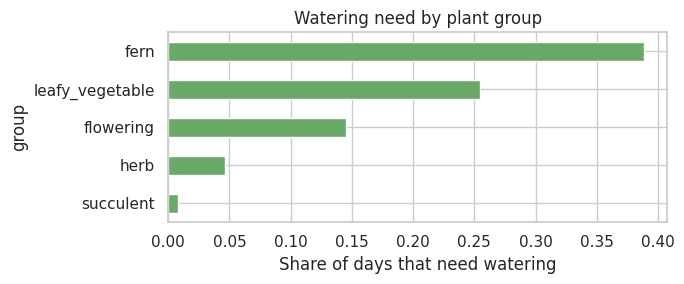

In [10]:
overall = data[TARGET].mean()
by_group = data.groupby("group")[TARGET].mean().sort_values()
print(f"Observation 2: overall, plants need watering on {overall:.1%} of days. By group:")
for g, v in by_group.items():
    print(f"   {g:16s} {v:6.1%} of days (about every {1/v:.1f} days)" if v > 0 else f"   {g:16s} never")

by_group.plot(kind="barh", color="#6aa86a", figsize=(7, 3))
plt.xlabel("Share of days that need watering"); plt.title("Watering need by plant group")
plt.tight_layout(); plt.show()


### 2.5 Observation 3: Watering labels by month
Compare the monthly watering rate with the rainfall pattern from Ian's section.


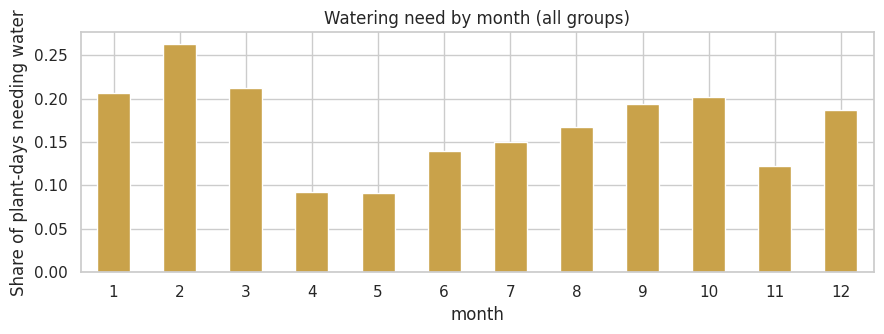

Observation 3: watering need peaks in Feb (26.3% of plant-days) and is lowest in May (9.1%). Correlation between monthly rain and monthly watering need: -0.70.


In [11]:
seasonal = data.assign(month=data["date"].dt.month).groupby("month")[TARGET].mean()
seasonal.plot(kind="bar", color="#c9a24a", figsize=(9, 3.5), rot=0)
plt.ylabel("Share of plant-days needing water"); plt.title("Watering need by month (all groups)")
plt.tight_layout(); plt.show()

print(f"Observation 3: watering need peaks in {name(seasonal.idxmax())} ({seasonal.max():.1%} of plant-days) "
      f"and is lowest in {name(seasonal.idxmin())} ({seasonal.min():.1%}). "
      f"Correlation between monthly rain and monthly watering need: "
      f"{np.corrcoef(monthly['rain_mm_per_year'], seasonal)[0, 1]:.2f}.")


### 2.6 Observation 4: Features linked to watering
Correlation helps describe patterns. It does not prove that a feature causes watering need.


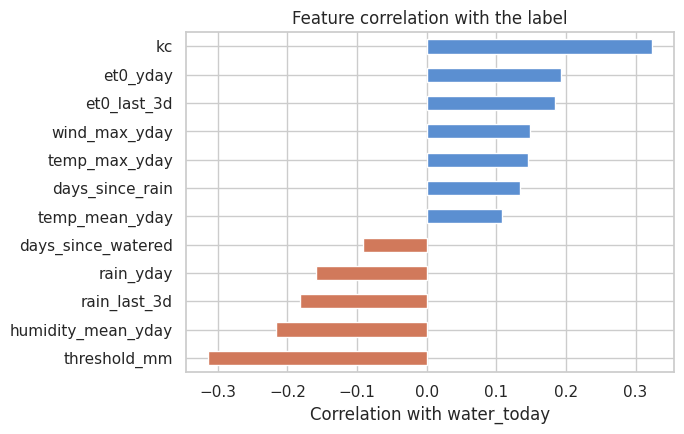

Observation 4: strongest positive links: kc (0.32), et0_yday (0.19), et0_last_3d (0.18)
               strongest negative links: threshold_mm (-0.31), humidity_mean_yday (-0.22), rain_last_3d (-0.18)


In [12]:
corr = data[FEATURES + [TARGET]].corr()[TARGET].drop(TARGET).sort_values()
corr.plot(kind="barh", color=["#d1795b" if v < 0 else "#5b8fd1" for v in corr], figsize=(7, 4.5))
plt.xlabel("Correlation with water_today"); plt.title("Feature correlation with the label")
plt.tight_layout(); plt.show()

print("Observation 4: strongest positive links:", ", ".join(f"{k} ({v:.2f})" for k, v in corr.tail(3)[::-1].items()))
print("               strongest negative links:", ", ".join(f"{k} ({v:.2f})" for k, v in corr.head(3).items()))


# Stage 4: Modelling
*Sections 3.1 and 3.2: split the data and tune the tree.*

### 3.1 Split: stratified random 80/20
We split the data randomly: 80% for training and 20% for testing. Stratified means both parts keep the same share of "water today" days.

In [13]:

train, test = train_test_split(data, test_size=0.2, stratify=data[TARGET], random_state=RANDOM_STATE)
X_train, y_train = train[FEATURES], train[TARGET]
X_test, y_test = test[FEATURES], test[TARGET]
print(f"Train: {len(train):,} rows, {y_train.mean():.1%} need water")
print(f"Test:  {len(test):,} rows, {y_test.mean():.1%} need water")

Train: 63,808 rows, 16.8% need water
Test:  15,952 rows, 16.8% need water


### 3.2 Tune the Decision Tree
We use stratified 5-fold cross-validation inside the training set: each fold takes a turn as the validation set. We choose depth (capped at 10 so the tree stays explainable), leaf size and class weighting using F1. The settings with the best cross-validated F1 give the final tree.

In [14]:
#5-fold cross-validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
param_grid = {"max_depth": [3, 4, 5, 6, 8, 10], "min_samples_leaf": [5, 20, 50, 100],
              "class_weight": [None, "balanced"]}
tree_search = GridSearchCV(DecisionTreeClassifier(random_state=RANDOM_STATE), param_grid,
                           scoring="f1", cv=cv, n_jobs=2, return_train_score=True, error_score="raise")
tree_search.fit(X_train, y_train)
best = tree_search.best_index_
res = tree_search.cv_results_
print("Best settings:", tree_search.best_params_)
print(f"Validation F1: {res['mean_test_score'][best]:.3f} +/- {res['std_test_score'][best]:.3f}")
print(f"Training F1:   {res['mean_train_score'][best]:.3f}")

Best settings: {'class_weight': None, 'max_depth': 8, 'min_samples_leaf': 20}
Validation F1: 0.684 +/- 0.005
Training F1:   0.701


# Stage 5: Evaluation
*Sections 3.3 to 3.7: test the tree, compare it with other models, and state the findings and limits.*

### 3.3 Test on held-out data
Precision measures correct watering alerts. Recall measures reference watering requests found. F1 balances the two.


              precision    recall  f1-score   support

 not yet (0)      0.932     0.949     0.940     13266
   water (1)      0.725     0.656     0.689      2686

    accuracy                          0.900     15952
   macro avg      0.828     0.803     0.815     15952
weighted avg      0.897     0.900     0.898     15952



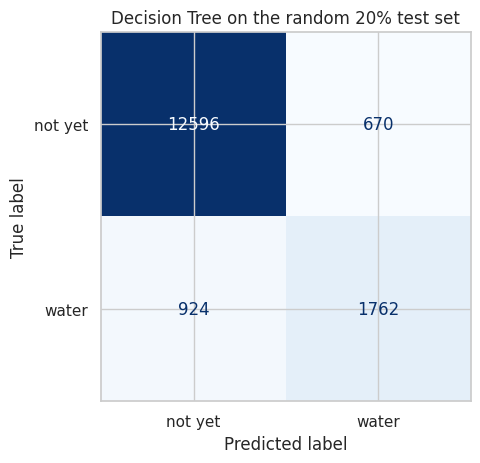

In [15]:
tree = tree_search.best_estimator_
y_pred_tree = tree.predict(X_test)

print(classification_report(y_test, y_pred_tree, target_names=["not yet (0)", "water (1)"], digits=3))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred_tree),
                       display_labels=["not yet", "water"]).plot(cmap="Blues", colorbar=False)
plt.title("Decision Tree on the random 20% test set"); plt.show()


### 3.4 Read the tree
The chart shows which inputs the tree uses most. The first levels show how it makes a decision.


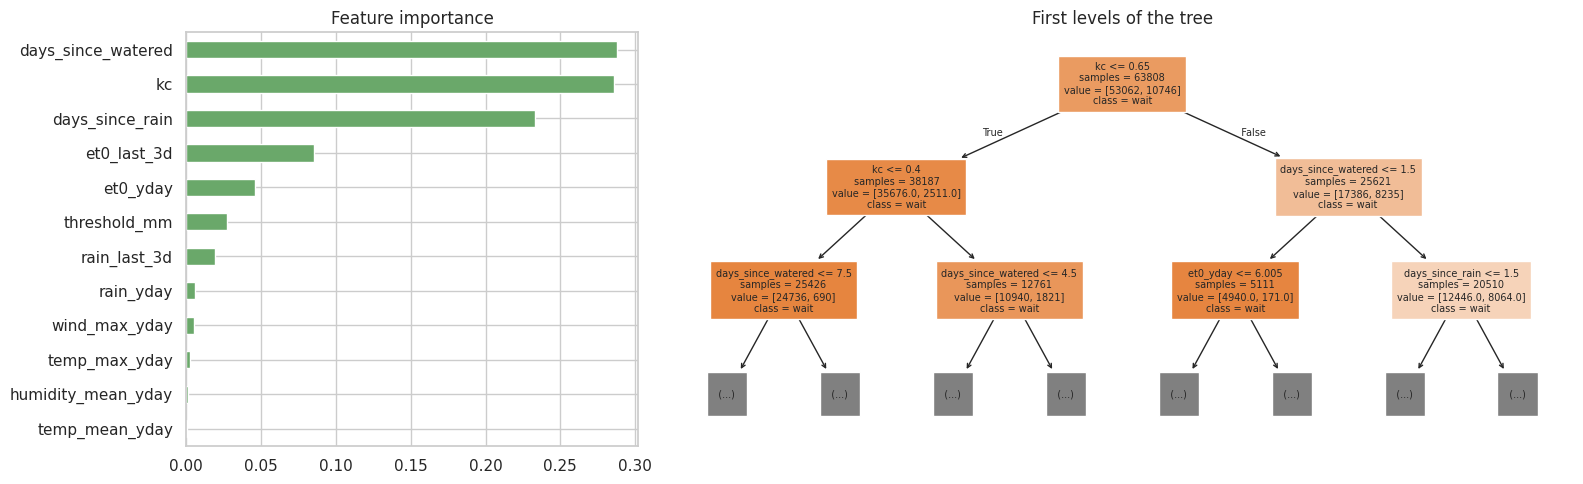

In [16]:
importance = pd.Series(tree.feature_importances_, index=FEATURES).sort_values()
fig, axes = plt.subplots(1, 2, figsize=(16, 5), gridspec_kw={"width_ratios": [1, 2]})
importance[importance > 0].plot(kind="barh", ax=axes[0], color="#6aa86a")
axes[0].set_title("Feature importance")
plot_tree(tree, feature_names=FEATURES, class_names=["wait", "water"],
          filled=True, max_depth=2, fontsize=7, ax=axes[1], impurity=False)
axes[1].set_title("First levels of the tree")
plt.tight_layout(); plt.show()


### 3.5 Compare the models
All classifiers use the same split, inputs and cross-validation folds. We also compare a chosen fixed calendar and an always-wait baseline. The direct rule generates the labels, so its perfect score is expected.


Logistic Regression best settings: {'model__C': 0.1, 'model__class_weight': 'balanced'}
K-Nearest Neighbours best settings: {'model__n_neighbors': 15, 'model__weights': 'distance'}
Random Forest best settings: {'class_weight': 'balanced', 'max_depth': 10, 'min_samples_leaf': 5}


,Accuracy,Balanced accuracy,Precision,Recall,F1,CV F1 mean,CV F1 std
Decision Tree,0.900,0.803,0.725,0.656,0.689,0.684,0.005
Logistic Regression,0.760,0.794,0.399,0.845,0.542,0.544,0.002
K-Nearest Neighbours,0.857,0.675,0.618,0.401,0.486,0.505,0.007
Random Forest,0.855,0.877,0.542,0.910,0.679,0.682,0.006
Chosen fixed calendar,0.675,0.552,0.221,0.367,0.276,NaN,NaN
Always do not water,0.832,0.500,0.000,0.000,0.000,NaN,NaN
"Direct rule, true values (upper bound)",1.000,1.000,1.000,1.000,1.000,NaN,NaN


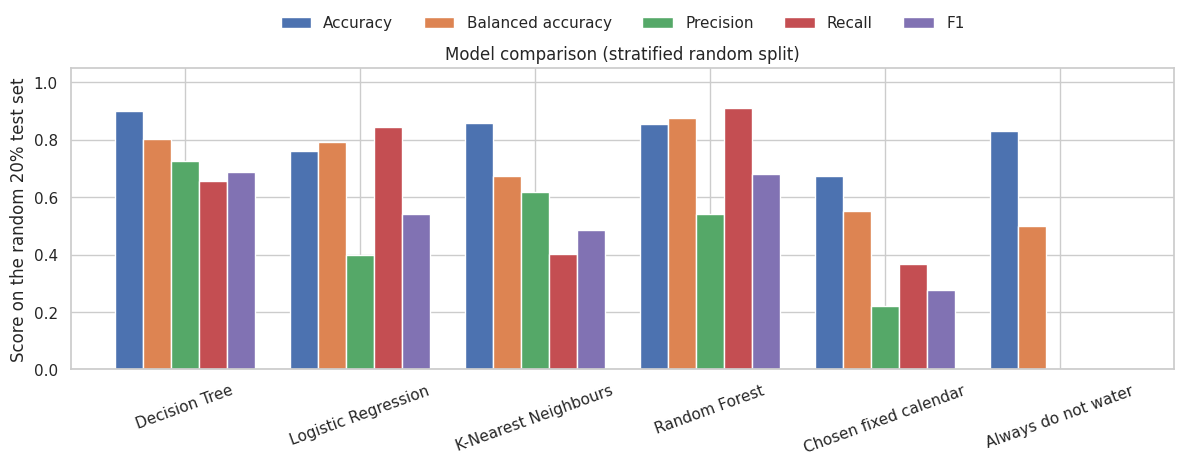

In [17]:
from sklearn.metrics import balanced_accuracy_score

candidates = {
    "Logistic Regression": (Pipeline([("scale", StandardScaler()),
        ("model", LogisticRegression(max_iter=3000, random_state=RANDOM_STATE))]),
        {"model__C": [0.1, 1, 10], "model__class_weight": [None, "balanced"]}),
    "K-Nearest Neighbours": (Pipeline([("scale", StandardScaler()), ("model", KNeighborsClassifier())]),
        {"model__n_neighbors": [15, 31, 61], "model__weights": ["uniform", "distance"]}),
    "Random Forest": (RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=2),
        {"max_depth": [6, 10], "min_samples_leaf": [5, 20], "class_weight": [None, "balanced"]})}
fitted = {"Decision Tree": tree}
cv_f1 = {"Decision Tree": (res["mean_test_score"][best], res["std_test_score"][best])}
for name, (model, grid) in candidates.items():
    search = GridSearchCV(model, grid, scoring="f1", cv=cv, n_jobs=2, error_score="raise").fit(X_train, y_train)
    fitted[name] = search.best_estimator_
    i = search.best_index_
    cv_f1[name] = (search.cv_results_["mean_test_score"][i], search.cv_results_["std_test_score"][i])
    print(name, "best settings:", search.best_params_)

def scores(y_true, y_pred):
    return {"Accuracy": accuracy_score(y_true, y_pred),
            "Balanced accuracy": balanced_accuracy_score(y_true, y_pred),
            "Precision": precision_score(y_true, y_pred, zero_division=0),
            "Recall": recall_score(y_true, y_pred, zero_division=0),
            "F1": f1_score(y_true, y_pred, zero_division=0)}

predictions = {name: m.predict(X_test) for name, m in fitted.items()}
predictions["Chosen fixed calendar"] = test["calendar_pred"].to_numpy()
predictions["Always do not water"] = DummyClassifier(strategy="constant", constant=0).fit(X_train, y_train).predict(X_test)
# The rule with the plant's TRUE values made the labels, so it is perfect by construction.
# The app can never know those true values; it is shown only as the upper bound.
predictions["Direct rule, true values (upper bound)"] = (test["deficit_mm"] >= test["true_threshold_mm"]).astype(int).to_numpy()
assert np.array_equal(predictions["Direct rule, true values (upper bound)"], y_test.to_numpy())

results = pd.DataFrame({name: scores(y_test, p) for name, p in predictions.items()}).T
results["CV F1 mean"] = [cv_f1[n][0] if n in cv_f1 else np.nan for n in results.index]
results["CV F1 std"] = [cv_f1[n][1] if n in cv_f1 else np.nan for n in results.index]
display(results.round(3))
results.to_csv("model_comparison.csv")

results.drop(index="Direct rule, true values (upper bound)")[["Accuracy", "Balanced accuracy", "Precision", "Recall", "F1"]].plot(
    kind="bar", figsize=(12, 5), rot=20, width=0.8)
plt.ylim(0, 1.05); plt.ylabel("Score on the random 20% test set")
plt.title("Model comparison (stratified random split)")
plt.legend(loc="upper center", bbox_to_anchor=(0.5, 1.22), ncol=5, frameon=False)
plt.tight_layout(); plt.show()

In [18]:
# Teaching baseline: a depth-2 tree, kept only as a comparison row. It is NOT the model in the app.
baseline_tree = DecisionTreeClassifier(max_depth=2, random_state=RANDOM_STATE).fit(X_train, y_train)
results.loc["Depth-2 tree (teaching baseline)"] = pd.Series(
    {**scores(y_test, baseline_tree.predict(X_test)), "CV F1 mean": np.nan, "CV F1 std": np.nan})
display(results.round(3))
results.to_csv("model_comparison.csv")

,Accuracy,Balanced accuracy,Precision,Recall,F1,CV F1 mean,CV F1 std
Decision Tree,0.900,0.803,0.725,0.656,0.689,0.684,0.005
Logistic Regression,0.760,0.794,0.399,0.845,0.542,0.544,0.002
K-Nearest Neighbours,0.857,0.675,0.618,0.401,0.486,0.505,0.007
Random Forest,0.855,0.877,0.542,0.910,0.679,0.682,0.006
Chosen fixed calendar,0.675,0.552,0.221,0.367,0.276,NaN,NaN
Always do not water,0.832,0.500,0.000,0.000,0.000,NaN,NaN
"Direct rule, true values (upper bound)",1.000,1.000,1.000,1.000,1.000,NaN,NaN
Depth-2 tree (teaching baseline),0.832,0.500,0.000,0.000,0.000,NaN,NaN


### 3.5b Robustness check: split by years
The random split lets neighbouring days land in both training and test. As a check, we train on 2015-2022 and test on 2023-2025 with the same tree settings. Similar scores mean the result does not depend on how we split.

In [19]:
# Same best tree settings, trained on 2015-2022 and tested on 2023-2025.
early = data[data["date"].dt.year <= 2022]
late = data[data["date"].dt.year >= 2023]
year_tree = DecisionTreeClassifier(random_state=RANDOM_STATE, **tree_search.best_params_).fit(early[FEATURES], early[TARGET])
year_pred = year_tree.predict(late[FEATURES])
split_check = pd.DataFrame({
    "Random 80/20 split": scores(y_test, predictions["Decision Tree"]),
    "Split by years (2023-2025)": scores(late[TARGET], year_pred)}).T.round(3)
display(split_check)

,Accuracy,Balanced accuracy,Precision,Recall,F1
Random 80/20 split,0.900,0.803,0.725,0.656,0.689
Split by years (2023-2025),0.898,0.783,0.751,0.608,0.672


### 3.5c Sanity check against the 60-75% guide
This is a check, not a target. We compare balanced accuracy with the guide, because plain accuracy starts from the always-wait floor.

In [20]:
# Sanity check, NOT a target: models scoring far above ~75% may be using a shortcut.
for name in ["Decision Tree", "Logistic Regression", "K-Nearest Neighbours", "Random Forest"]:
    acc, bal = results.loc[name, "Accuracy"], results.loc[name, "Balanced accuracy"]
    note = "within" if 0.60 <= bal <= 0.75 else ("above" if bal > 0.75 else "below")
    print(f"{name:22s} accuracy {acc:.1%} | balanced accuracy {bal:.1%}")
print("\nAlways-do-not-water accuracy:", f"{results.loc['Always do not water', 'Accuracy']:.1%}",
      "(the floor plain accuracy starts from)")

Decision Tree          accuracy 90.0% | balanced accuracy 80.3%
Logistic Regression    accuracy 76.0% | balanced accuracy 79.4%
K-Nearest Neighbours   accuracy 85.7% | balanced accuracy 67.5%
Random Forest          accuracy 85.5% | balanced accuracy 87.7%

Always-do-not-water accuracy: 83.2% (the floor plain accuracy starts from)


### 3.6 Findings and next steps
Scores show agreement with simulated labels under reference watering history. They do not yet show real plant health or morning forecast performance.

Next: test morning forecasts, let each method follow its own watering history, vary the soil assumptions, and check predictions against real plants.


**How to read the scores:** plain accuracy starts from the always-wait floor, so we judge the tree by balanced accuracy and F1. We checked that no input uses today's weather or the hidden true plant values, and the year-split check in 3.5b shows the result does not depend only on the random split.

In [21]:
tree_row = results.loc["Decision Tree"]
print(f"Random split: accuracy {tree_row['Accuracy']:.1%}, balanced accuracy {tree_row['Balanced accuracy']:.1%}, F1 {tree_row['F1']:.3f}")
print(f"Year split (2023-2025): F1 {split_check.loc['Split by years (2023-2025)', 'F1']:.3f}")
print(f"Chosen calendar: F1 {results.loc['Chosen fixed calendar', 'F1']:.3f}")
print(f"Always-wait accuracy: {results.loc['Always do not water', 'Accuracy']:.1%}")
print("Labels are simulated from real Nairobi weather with plant variation and gardener behaviour.")
print("A field trial is still needed before claiming practical improvement.")

Random split: accuracy 90.0%, balanced accuracy 80.3%, F1 0.689
Year split (2023-2025): F1 0.672
Chosen calendar: F1 0.276
Always-wait accuracy: 83.2%
Labels are simulated from real Nairobi weather with plant variation and gardener behaviour.
A field trial is still needed before claiming practical improvement.


### 3.7 Limitations

In [22]:
print("Limitations")
print("1. Labels are simulated (water-balance rule + imperfect gardener), not observed on real plants.")
print(f"2. The random split lets neighbouring days into both train and test. Chronological check "
      f"(train 2015-2022, test 2023-2025): F1 {split_check.loc['Split by years (2023-2025)', 'F1']:.3f} "
      f"vs {results.loc['Decision Tree', 'F1']:.3f} on the random split.")
print("3. Inputs here are completed historical days; real forecasts will be less exact.")
print("4. Real-world validation with gardeners' check-ins is the next step.")

Limitations
1. Labels are simulated (water-balance rule + imperfect gardener), not observed on real plants.
2. The random split lets neighbouring days into both train and test. Chronological check (train 2015-2022, test 2023-2025): F1 0.672 vs 0.689 on the random split.
3. Inputs here are completed historical days; real forecasts will be less exact.
4. Real-world validation with gardeners' check-ins is the next step.


# Stage 6: Deployment
## Appendix: Model files
The JSON contains the complete tree. Its predictions are checked against Python before export. The app reads `decision_tree.json`. `android_parity_cases.json` holds one real case for every leaf plus cases on each split boundary, so the Kotlin tree can be checked against this Python model.


In [23]:
import joblib
joblib.dump({"model": tree, "features": FEATURES, "versions": VERSIONS}, "decision_tree.joblib")
feature_units = ["C", "C", "%", "km/h", "mm", "mm", "mm", "mm", "days", "days", "ratio", "mm"]
t = tree.tree_
exported = {"schema_version": 1, "features": FEATURES, "feature_units": feature_units,
    "classes": tree.classes_.tolist(), "input_dtype": "float32",
    "scope": "Morning-only inputs, individual plant variation, imperfect gardener; synthetic labels from real Nairobi weather",
    "children_left": t.children_left.tolist(), "children_right": t.children_right.tolist(),
    "feature": t.feature.tolist(), "threshold": t.threshold.tolist(),
    "predicted_class": [int(tree.classes_[np.argmax(v[0])]) for v in t.value],
    "versions": VERSIONS, "weather_sha256": provenance["sha256"],
    "plant_parameters": plants.to_dict(orient="records"), "available_water_fraction": AVAILABLE_WATER,
    "min_effective_rain_mm": MIN_EFFECTIVE_RAIN}
Path("decision_tree.json").write_text(json.dumps(exported, indent=2))
# Reload the actual serialized representation and verify its traversal.
loaded = json.loads(Path("decision_tree.json").read_text())
def predict_export(row):
    row = np.asarray(row, dtype=np.float32)
    assert len(row) == len(FEATURES) and np.isfinite(row).all()
    node = 0
    while loaded["children_left"][node] != -1:
        f = loaded["feature"][node]
        node = loaded["children_left"][node] if float(row[f]) <= loaded["threshold"][node] else loaded["children_right"][node]
    return loaded["predicted_class"][node]
export_predictions = np.array([predict_export(row) for row in X_test.to_numpy()])
assert np.array_equal(export_predictions, y_pred_tree), "JSON predictions differ from the Python model."
Path("decision_tree_rules.txt").write_text(export_text(tree, feature_names=FEATURES,
                                                        max_depth=tree.get_depth(), decimals=17))
# Parity cases: one real row per leaf (every branch is exercised) plus split-boundary cases
X_ref = pd.concat([X_test, X_train]).astype("float32")       # test rows first, then training rows
leaf_ref = tree.apply(X_ref)
first_row_of_leaf = pd.Series(np.arange(len(X_ref))).groupby(leaf_ref).first()
case_rows = [X_ref.iloc[int(i)].to_numpy() for i in first_row_of_leaf.to_numpy()]

reach = tree.decision_path(X_ref).tocsc()                      # which rows pass through each node
for node in range(t.node_count):
    if t.children_left[node] == -1:
        continue                                               # leaves have no split to test
    base = X_ref.iloc[int(reach[:, node].indices[0])].to_numpy()
    th32 = np.float32(t.threshold[node])
    for v in (th32, np.nextafter(th32, np.float32(np.inf))):   # exactly on the threshold, and just above it
        r = base.copy(); r[t.feature[node]] = v
        case_rows.append(r)

case_matrix = np.unique(np.array(case_rows, dtype="float32"), axis=0)
expected = tree.predict(pd.DataFrame(case_matrix, columns=FEATURES))
cases = [{"features": [float(x) for x in row], "expected_class": int(e)} for row, e in zip(case_matrix, expected)]
assert all(predict_export(c["features"]) == c["expected_class"] for c in cases), "JSON disagrees with a parity case."
Path("android_parity_cases.json").write_text(json.dumps({"feature_order": FEATURES, "cases": cases}, indent=2))
print(len(cases), "parity cases written (one per leaf plus split-boundary cases).")
Path("run_versions.json").write_text(json.dumps({"python": platform.python_version(), "packages": VERSIONS}, indent=2))
print("JSON export matches all", len(X_test), "test predictions.")
print("Depth:", tree.get_depth(), "Leaves:", tree.get_n_leaves())
print("Saved model, full rules, JSON, Android parity cases, comparison scores and runtime versions.")


508 parity cases written (one per leaf plus split-boundary cases).
JSON export matches all 15952 test predictions.
Depth: 8 Leaves: 170
Saved model, full rules, JSON, Android parity cases, comparison scores and runtime versions.


### Feature contract for the app
The app must build the 12 inputs in exactly this order and these units.

| # | Feature | Unit | How the app gets it |
|---|---|---|---|
| 0 | temp_mean_yday | °C | Open-Meteo, yesterday's mean temperature |
| 1 | temp_max_yday | °C | Open-Meteo, yesterday's max temperature |
| 2 | humidity_mean_yday | % | Open-Meteo, yesterday's mean relative humidity |
| 3 | wind_max_yday | km/h | Open-Meteo, yesterday's max wind speed |
| 4 | rain_yday | mm | Open-Meteo, yesterday's precipitation |
| 5 | rain_last_3d | mm | Sum of precipitation over the 3 days before today |
| 6 | et0_yday | mm | Open-Meteo, yesterday's ET0 |
| 7 | et0_last_3d | mm | Sum of ET0 over the 3 days before today |
| 8 | days_since_rain | days | Days since a day with at least 2 mm rain, counted up to yesterday |
| 9 | days_since_watered | days | From the plant's last "watered" check-in in the app's database |
| 10 | kc | ratio | From the species table in the app |
| 11 | threshold_mm | mm | From the species table in the app |

Output: 1 = water now, 0 = not yet.

### How the model explains a decision
The tree is a chain of yes/no questions, so every answer can be traced. The cell below prints the path for a few plants. It is the same logic as the app's "Why?" card. The percentage is the share of training days in that leaf that really needed water, and the fixed schedule is shown for comparison.

In [24]:
FEATURE_WORDS = {
    "temp_mean_yday": "yesterday's mean temperature (C)", "temp_max_yday": "yesterday's max temperature (C)",
    "humidity_mean_yday": "yesterday's humidity (%)", "wind_max_yday": "yesterday's max wind (km/h)",
    "rain_yday": "yesterday's rain (mm)", "rain_last_3d": "rain in the last 3 days (mm)",
    "et0_yday": "yesterday's evaporation, ET0 (mm)", "et0_last_3d": "evaporation over the last 3 days (mm)",
    "days_since_rain": "days since a rain of 2 mm or more", "days_since_watered": "days since last watered",
    "kc": "plant water-use factor, Kc", "threshold_mm": "how much soil dryness the species tolerates (mm)"}

PRESETS = {
    "Dry week":   dict(temp_mean_yday=21.5, temp_max_yday=29, humidity_mean_yday=50, wind_max_yday=20,
                       rain_yday=0, rain_last_3d=0, et0_yday=6.0, et0_last_3d=17.5, days_since_rain=12),
    "Rainy week": dict(temp_mean_yday=18.5, temp_max_yday=22, humidity_mean_yday=85, wind_max_yday=12,
                       rain_yday=15, rain_last_3d=30, et0_yday=3.0, et0_last_3d=9.5, days_since_rain=0)}

# Share of training days in each leaf that really needed water (raw share, not the class-weighted one)
leaf_of_train = tree.apply(X_train.astype("float32"))
leaf_water_share = pd.Series(y_train.to_numpy()).groupby(leaf_of_train).mean()

def explain(group, days_since_watered, preset):
    sp = plants.set_index("group").loc[group]
    row = {**PRESETS[preset], "days_since_watered": days_since_watered, "kc": sp["kc"], "threshold_mm": sp["threshold_mm"]}
    X = pd.DataFrame([row])[FEATURES].astype("float32")
    path = tree.decision_path(X).indices                    # the nodes this plant passes through, root to leaf
    print(f"--- {group}, last watered {days_since_watered} days ago, {preset} ---")
    for node in path[:-1]:
        f, th = tree.tree_.feature[node], tree.tree_.threshold[node]
        val = float(X.iloc[0, f])
        print(f"  {FEATURE_WORDS[FEATURES[f]]} = {val:.1f}  ->  is it <= {th:.2f}?  {'yes' if val <= th else 'no'}")
    answer = "WATER NOW" if tree.predict(X)[0] == 1 else "NOT YET"
    share = leaf_water_share[path[-1]]
    schedule = "water" if days_since_watered >= sp["schedule_days"] else "not yet"
    print(f"  => {answer}  (in training, {share:.0%} of the days that ended in this leaf needed water)")
    print(f"     A fixed {int(sp['schedule_days'])}-day schedule would say: {schedule}\n")

explain("fern", 3, "Dry week")
explain("fern", 3, "Rainy week")
explain("leafy_vegetable", 3, "Dry week")
explain("leafy_vegetable", 7, "Dry week")
explain("succulent", 14, "Dry week")

--- fern, last watered 3 days ago, Dry week ---
  plant water-use factor, Kc = 0.8  ->  is it <= 0.65?  no
  days since last watered = 3.0  ->  is it <= 1.50?  no
  days since a rain of 2 mm or more = 12.0  ->  is it <= 1.50?  no
  days since last watered = 3.0  ->  is it <= 3.50?  yes
  plant water-use factor, Kc = 0.8  ->  is it <= 0.90?  yes
  yesterday's evaporation, ET0 (mm) = 6.0  ->  is it <= 4.71?  no
  days since last watered = 3.0  ->  is it <= 2.50?  no
  yesterday's evaporation, ET0 (mm) = 6.0  ->  is it <= 5.06?  no
  => WATER NOW  (in training, 96% of the days that ended in this leaf needed water)
     A fixed 3-day schedule would say: water

--- fern, last watered 3 days ago, Rainy week ---
  plant water-use factor, Kc = 0.8  ->  is it <= 0.65?  no
  days since last watered = 3.0  ->  is it <= 1.50?  no
  days since a rain of 2 mm or more = 0.0  ->  is it <= 1.50?  yes
  rain in the last 3 days (mm) = 30.0  ->  is it <= 9.05?  no
  yesterday's rain (mm) = 15.0  ->  is it

### Accepted inputs
The model should only see realistic values. These limits come from the data checks in section 1.4. The app applies the same limits and shows a friendly message instead of predicting when an input is outside them.

In [25]:
ACCEPTED_INPUTS = {   # (minimum, maximum); None means no upper limit
    "temp_mean_yday": (-5, 45), "temp_max_yday": (-5, 45), "humidity_mean_yday": (0, 100),
    "wind_max_yday": (0, None), "rain_yday": (0, None), "rain_last_3d": (0, None),
    "et0_yday": (0, None), "et0_last_3d": (0, None),
    "days_since_rain": (0, None), "days_since_watered": (1, None)}
SPECIES = list(plants["group"])

def validate_inputs(species, values):
    """Return a list of problems; an empty list means the inputs may go to the model."""
    problems = []
    if species not in SPECIES:
        problems.append(f"Unknown species '{species}'. Choose one of: {', '.join(SPECIES)}")
    for name, (lo, hi) in ACCEPTED_INPUTS.items():
        v = values.get(name)
        if v is None or not np.isfinite(v):
            problems.append(f"{name} is missing"); continue
        if lo is not None and v < lo: problems.append(f"{name} = {v} is below the minimum {lo}")
        if hi is not None and v > hi: problems.append(f"{name} = {v} is above the maximum {hi}")
    return problems

# The limits must agree with the data the model was trained on
rows = []
for name, (lo, hi) in ACCEPTED_INPUTS.items():
    dmin, dmax = data[name].min(), data[name].max()
    assert (lo is None or dmin >= lo) and (hi is None or dmax <= hi), f"Training data outside the limits for {name}"
    rows.append({"feature": name, "min allowed": lo, "max allowed": hi, "data min": round(dmin, 1), "data max": round(dmax, 1)})
display(pd.DataFrame(rows))

print(validate_inputs("fern", {**PRESETS["Dry week"], "days_since_watered": 3}))      # [] means valid
print(validate_inputs("fern", {**PRESETS["Dry week"], "days_since_watered": 3, "humidity_mean_yday": 140, "rain_yday": -2}))
print(validate_inputs("cactus", {**PRESETS["Dry week"], "days_since_watered": 3, "wind_max_yday": float("nan")}))

,feature,min allowed,max allowed,data min,data max
0,temp_mean_yday,-5,45.0,15.4,23.9
1,temp_max_yday,-5,45.0,17.0,32.2
2,humidity_mean_yday,0,100.0,35.0,94.0
3,wind_max_yday,0,NaN,4.5,26.3
4,rain_yday,0,NaN,0.0,42.1
5,rain_last_3d,0,NaN,0.0,70.5
6,et0_yday,0,NaN,1.2,7.7
7,et0_last_3d,0,NaN,5.4,23.0
8,days_since_rain,0,NaN,0.0,115.0
9,days_since_watered,1,NaN,1.0,110.0


[]
['humidity_mean_yday = 140 is above the maximum 100', 'rain_yday = -2 is below the minimum 0']
["Unknown species 'cactus'. Choose one of: succulent, herb, flowering, fern, leafy_vegetable", 'wind_max_yday is missing']


### Sources
- [Open-Meteo: historical weather](https://open-meteo.com/en/docs/historical-weather-api)
- [Allen et al. (1998): FAO-56](https://www.fao.org/4/X0490E/X0490E00.htm)
- [WUCOLS: landscape water use](https://ucanr.edu/sites/WUCOLS/)
- [Scikit-learn: cross-validation](https://scikit-learn.org/stable/modules/cross_validation.html)


